# 02 - Baseline: TF-IDF + Logistic Regression

| Step | Details |
|---|---|
| Validation | fixed split from `common.split_train_val` |
| Features | TF-IDF word 1-2 / char_wb 2-5 n-grams |
| Model | LogisticRegression, grid over `C` by macro-F1 |
| Outputs | per-class report, confusion matrix, `submission_baseline.csv`, probabilities in `outputs/` |

- Vectorizers are fitted **on the train part only** (no leakage)
- Shared code: `src/common.py`

## Setup

In [1]:
import subprocess
import sys

REPO = "https://github.com/mohinska/ai_hw3_AIGenTextDetection.git"
REPO_DIR = "/tmp/repo"

subprocess.run(["rm", "-rf", REPO_DIR], check=True)
subprocess.run(["git", "clone", "-q", "--depth", "1", REPO, REPO_DIR], check=True)
sys.path.insert(0, f"{REPO_DIR}/src")

In [2]:
import os
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, f1_score
from sklearn.model_selection import ParameterGrid
from tqdm.auto import tqdm

import common
from common import LABELS, TEXT_COL, LABEL_COL, SEED
from features import fit_tfidf, tfidf_transform

warnings.filterwarnings("ignore", category=UserWarning)

## Config

In [3]:
FINAL = True             # True: final run - whole train part, only the best config (char_wb_2-5, C=2)
N_TRAIN = None if FINAL else 60_000   # stratified subsample of the train part used for fitting
NAME = "baseline_full" if FINAL else "baseline"   # name of the saved probabilities / submission

FEATURE_SETS = {"word_1-2": ["word_1-2"],
                "char_wb_2-5": ["char_wb_2-5"],
                "word+char": ["word_1-2", "char_wb_2-5"]}
GRID = {"C": [0.5, 2.0, 8.0]}
if FINAL:
    FEATURE_SETS = {"char_wb_2-5": ["char_wb_2-5"]}
    GRID = {"C": [2.0]}

OUT_DIR = os.path.join(common.WORK_DIR, "outputs")
SUBMISSION_PATH = os.path.join(common.WORK_DIR, f"submission_{NAME}.csv")
os.makedirs(OUT_DIR, exist_ok=True)

## Load data

In [4]:
train_df, test_df, sample_sub = common.load_data()
LANG_COL = common.lang_col(train_df)

assert set(train_df[LABEL_COL].unique()) == set(LABELS), train_df[LABEL_COL].unique()
print("train:", train_df.shape, "| test:", test_df.shape, "| columns:", list(train_df.columns))
train_df[LABEL_COL].value_counts(normalize=True).round(3)

train: (272352, 5) | test: (25000, 4) | columns: ['id', 'text', 'lang', 'domain', 'label']


label
ai        0.448
fusion    0.307
human     0.245
Name: proportion, dtype: float64

## Fixed validation split

| Parameter | Value |
|---|---|
| Size | 10% of train.csv |
| Stratified by | label + language |
| Seed | 42 |


In [5]:
trn, val = common.split_train_val(train_df)
trn = common.subsample(trn, N_TRAIN)
print(f"train part: {len(trn):,} | val: {len(val):,}")

train part: 245,116 | val: 27,236


In [6]:
texts = {"train": trn[TEXT_COL].fillna(""), "val": val[TEXT_COL].fillna(""), "test": test_df[TEXT_COL].fillna("")}
y_trn, y_val = trn[LABEL_COL].to_numpy(), val[LABEL_COL].to_numpy()

## Parameter search

- Each vectorizer is fitted once on the train part; validation is only transformed
- Configs (`FEATURE_SETS` x `GRID`) are a flat list; the best model is kept, no refit

In [7]:
def fit_logreg(X, y, C):
    """Logistic regression with the fixed settings used across the project."""
    return LogisticRegression(C=C, max_iter=2000, random_state=SEED).fit(X, y)


def run_grid():
    """Fit every (feature set, params) config; return the results table and the best model.
    Configs are ordered by feature set, so only one pair of TF-IDF matrices is in RAM at a time."""
    vectorizers = fit_tfidf({n for names in FEATURE_SETS.values() for n in names}, texts["train"])  # train only
    configs = [(fs, params) for fs in FEATURE_SETS for params in ParameterGrid(GRID)]
    rows, best, current, X = [], {"macro_f1": -1.0}, None, None
    for feature_set, params in tqdm(configs, desc="grid"):
        if feature_set != current:
            X = None                                   # free the previous matrices first
            vecs = {n: vectorizers[n] for n in FEATURE_SETS[feature_set]}
            X = {"train": tfidf_transform(vecs, texts["train"]), "val": tfidf_transform(vecs, texts["val"])}
            current = feature_set
        t0 = time.time()
        clf = fit_logreg(X["train"], y_trn, **params)
        proba = clf.predict_proba(X["val"])
        f1 = f1_score(y_val, clf.classes_[proba.argmax(1)], average="macro")
        rows.append({"features": feature_set, **params, "n_feats": X["train"].shape[1],
                     "macro_f1": round(f1, 4), "fit_s": round(time.time() - t0, 1)})
        if f1 > best["macro_f1"]:                      # keep the best model: no refit later (RAM)
            best = {"macro_f1": f1, "features": feature_set, "clf": clf, "val_proba": proba, "vecs": vecs}
    results = pd.DataFrame(rows).sort_values("macro_f1", ascending=False).reset_index(drop=True)
    return results, best


results_df, best = run_grid()
results_df.to_csv(os.path.join(OUT_DIR, "baseline_grid.csv"), index=False)
results_df

,features,C,n_feats,macro_f1,fit_s
0,char_wb_2-5,2.0,300000,0.8951,2403.8


## Best model on the validation split

In [8]:
best_clf, val_proba = best["clf"], best["val_proba"]
val_pred = best_clf.classes_[val_proba.argmax(1)]
print(f"best: {best['features']}, C={best_clf.C} -> val macro-F1 = {best['macro_f1']:.4f}\n")
print(classification_report(y_val, val_pred, labels=LABELS, digits=4))

best: char_wb_2-5, C=2.0 -> val macro-F1 = 0.8951

              precision    recall  f1-score   support

       human     0.8124    0.8707    0.8405      6673
          ai     0.9869    0.9922    0.9895     12195
      fusion     0.8850    0.8273    0.8552      8368

    accuracy                         0.9118     27236
   macro avg     0.8947    0.8967    0.8951     27236
weighted avg     0.9128    0.9118    0.9117     27236



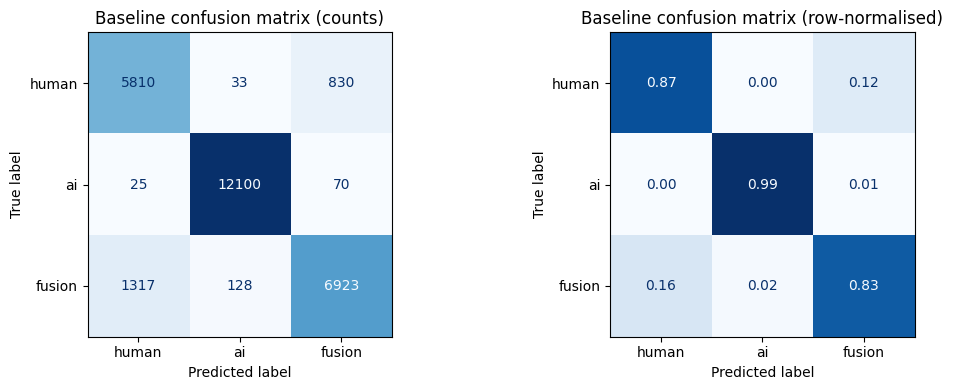

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, norm, title in zip(axes, [None, "true"], ["counts", "row-normalised"]):
    ConfusionMatrixDisplay.from_predictions(y_val, val_pred, labels=LABELS, normalize=norm,
                                            values_format=".2f" if norm else "d",
                                            cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(f"Baseline confusion matrix ({title})")
common.save_fig("baseline_cm.png")

In [10]:
# macro-F1 per language and per domain: where the model is weak
for col in [LANG_COL, "domain"]:
    if col in val.columns:
        display(common.f1_by(y_val, val_pred, val[col]))

,n,macro_f1
g,,
en-EN,21959,0.8888
de-DE,5277,0.9179


,n,macro_f1
g,,
blog_authorship_corpus,4022,0.7645
gutenberg,778,0.8304
house_of_commons,3229,0.8926
arxiv_papers,1428,0.8946
student_essays,5433,0.9124
bundestag,5229,0.9181
euro_court_cases,2757,0.9192
cnn_news,4360,0.9440


In [11]:
# Save validation probabilities: reused later for ensembling / threshold tuning
common.save_proba(val["id"], val_proba, best_clf.classes_, NAME, "val")

## Predict test and write submission

In [12]:
test_proba = best_clf.predict_proba(tfidf_transform(best["vecs"], texts["test"]))
test_pred = best_clf.classes_[test_proba.argmax(1)]
common.save_proba(test_df["id"], test_proba, best_clf.classes_, NAME, "test")

submission = common.save_submission(test_df["id"], test_pred, sample_sub, SUBMISSION_PATH)
print("saved", SUBMISSION_PATH, submission.shape)
submission["label"].value_counts(normalize=True).round(3)

saved /kaggle/working/submission_baseline_full.csv (25000, 2)


label
ai        0.517
human     0.264
fusion    0.219
Name: proportion, dtype: float64

## Conclusions

Experiment run (`FINAL = False`, 60k texts, outputs replaced by the final run):

- **Best config:** `char_wb_2-5`, `C=2` -> val macro-F1 0.8724 (`word+char` 0.8723, `word_1-2` 0.8467). Char n-grams carry the signal -> reference for `04` / `06`
- **LB vs val:** public LB 0.86898 vs val 0.8724, scores are close so fixed split is reliable
- **Per class:** `ai` 0.984, `fusion` 0.824, `human` 0.809 -> `ai` is solved, `human` vs `fusion` is the hard part
- **Fusion under-predicted:** recall 0.79 vs 0.84 for `human` -> try class weights / scaling (`04`, `05`)
- **Weak domains:** `blog_authorship_corpus` 0.75, `gutenberg` 0.80; `gutenberg` is 3x larger in test
- **Languages:** `en` 0.866 vs `de` 0.895
- **Test predictions:** `ai` 51.8% vs 44.8% in train -> partly explained by more ai-heavy domains in test (`gutenberg` 7.4%, `arxiv_papers` 6.7%)

Final run (`FINAL = True`, 245k texts, outputs above):

- **More data:** val macro-F1 0.8951 vs 0.8724 on 60k (+0.023), every class improves: `human` 0.841, `ai` 0.990, `fusion` 0.855
- **Biggest gain on `arxiv_papers`:** 0.851 -> 0.895; `blog_authorship_corpus` stays the weakest (0.765)